In [1]:
import sys, torch

print("Python:", sys.executable)
print("Torch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Python: c:\Users\Admin\Desktop\iitb_fellowship\venv\Scripts\python.exe
Torch: 2.7.1+cu118
CUDA: True
GPU: NVIDIA RTX 4500 Ada Generation


In [2]:
import os
import time
import copy

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader


In [3]:
DATA_DIR = "../data"
TRAIN_DIR = os.path.join(DATA_DIR, "train")
VAL_DIR   = os.path.join(DATA_DIR, "val")

BATCH_SIZE = 64
NUM_EPOCHS = 10
NUM_WORKERS = 8
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [4]:
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


In [5]:
train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=train_transforms)
val_dataset   = datasets.ImageFolder(VAL_DIR, transform=val_transforms)

class_names = train_dataset.classes
num_classes = len(class_names)

print("Classes:", class_names)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)


Classes: ['Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


In [6]:
model = models.convnext_tiny(weights="IMAGENET1K_V1")

for param in model.parameters():
    param.requires_grad = True

model.classifier[2] = nn.Linear(
    model.classifier[2].in_features,
    num_classes
)

model = model.to(DEVICE)
criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-4,          # lower LR for fine-tuning, mag ajun jasta load deta yeil GPU la 
    weight_decay=1e-4
)


scaler = torch.cuda.amp.GradScaler()


C:\Users\Admin\AppData\Local\Temp\ipykernel_5916\2533382272.py:21: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


In [7]:
best_acc = 0.0
best_model_wts = copy.deepcopy(model.state_dict())

for epoch in range(NUM_EPOCHS):
    start_time = time.time()

    print(f"\nEpoch {epoch+1}/{NUM_EPOCHS}")
    print("-" * 30)

    for phase in ["train", "val"]:
        if phase == "train":
            model.train()
            loader = train_loader
        else:
            model.eval()
            loader = val_loader

        running_loss = 0.0
        running_corrects = 0

        for inputs, labels in loader:
            inputs = inputs.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            optimizer.zero_grad()

            with torch.set_grad_enabled(phase == "train"):
                with torch.cuda.amp.autocast():
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)
                    _, preds = torch.max(outputs, 1)

                if phase == "train":
                    scaler.scale(loss).backward()
                    scaler.step(optimizer)
                    scaler.update()

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels)

        epoch_loss = running_loss / len(loader.dataset)
        epoch_acc = running_corrects.double() / len(loader.dataset)

        print(f"{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}")

        if phase == "val" and epoch_acc > best_acc:
            best_acc = epoch_acc
            best_model_wts = copy.deepcopy(model.state_dict())

    epoch_time = time.time() - start_time
    print(f"⏱ Epoch time: {epoch_time/60:.2f} minutes")

print("\n Best val accuracy:", best_acc)
model.load_state_dict(best_model_wts)



Epoch 1/10
------------------------------


C:\Users\Admin\AppData\Local\Temp\ipykernel_5916\3819688404.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


train Loss: 0.3555 Acc: 0.9049
val Loss: 0.0761 Acc: 0.9733
⏱ Epoch time: 0.91 minutes

Epoch 2/10
------------------------------
train Loss: 0.0427 Acc: 0.9877
val Loss: 0.0238 Acc: 0.9912
⏱ Epoch time: 0.90 minutes

Epoch 3/10
------------------------------
train Loss: 0.0249 Acc: 0.9925
val Loss: 0.0703 Acc: 0.9804
⏱ Epoch time: 0.90 minutes

Epoch 4/10
------------------------------
train Loss: 0.0152 Acc: 0.9962
val Loss: 0.0075 Acc: 0.9971
⏱ Epoch time: 0.90 minutes

Epoch 5/10
------------------------------
train Loss: 0.0062 Acc: 0.9986
val Loss: 0.0074 Acc: 0.9975
⏱ Epoch time: 0.90 minutes

Epoch 6/10
------------------------------
train Loss: 0.0033 Acc: 0.9995
val Loss: 0.0101 Acc: 0.9962
⏱ Epoch time: 0.90 minutes

Epoch 7/10
------------------------------
train Loss: 0.0213 Acc: 0.9945
val Loss: 0.0540 Acc: 0.9837
⏱ Epoch time: 0.90 minutes

Epoch 8/10
------------------------------
train Loss: 0.0115 Acc: 0.9968
val Loss: 0.0096 Acc: 0.9971
⏱ Epoch time: 0.90 minutes

Ep

<All keys matched successfully>

In [8]:
os.makedirs("../models", exist_ok=True)

torch.save(
    model.state_dict(),
    "../models/convnext_tomato_best.pth"
)

print("Model saved to models/convnext_tomato_best.pth")


Model saved to models/convnext_tomato_best.pth


In [9]:
from torchvision import datasets
from torch.utils.data import DataLoader

TEST_DIR = "../data/test"

test_dataset = datasets.ImageFolder(
    TEST_DIR,
    transform=val_transforms
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=8,
    pin_memory=True
)

model.eval()
correct = 0
total = 0

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)

        correct += torch.sum(preds == labels)
        total += labels.size(0)

test_acc = correct.double() / total
print(f"Test Accuracy: {test_acc:.4f}")


Test Accuracy: 0.9992


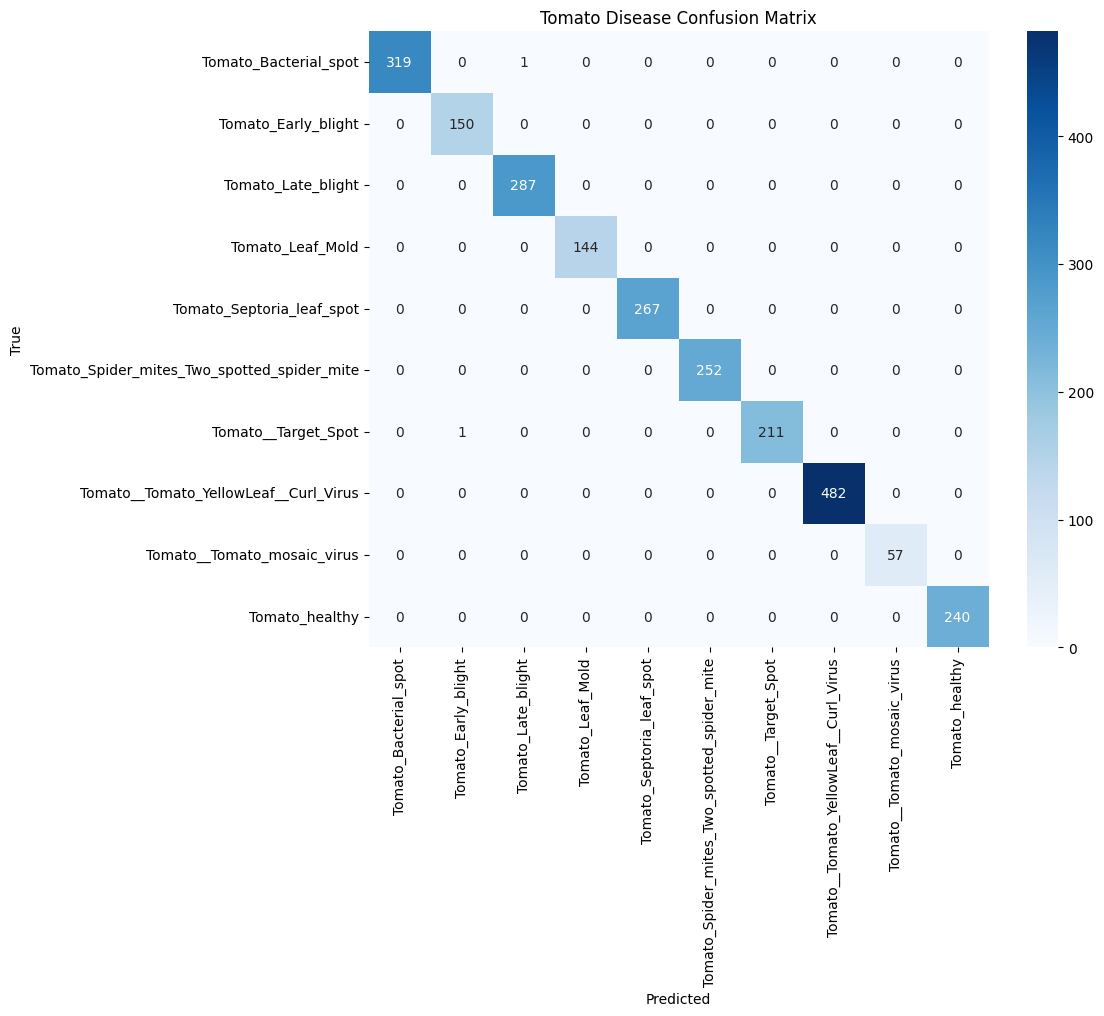

FileNotFoundError: [Errno 2] No such file or directory: 'outputs/confusion_matrix.png'

<Figure size 640x480 with 0 Axes>

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(DEVICE)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    xticklabels=test_dataset.classes,
    yticklabels=test_dataset.classes,
    annot=True,
    fmt="d",
    cmap="Blues"
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Tomato Disease Confusion Matrix")
plt.show()

print(classification_report(
    all_labels,
    all_preds,
    target_names=test_dataset.classes
))
